# Canonical XGBoost LOSO Experiment

This notebook uses **one fixed XGBoost configuration** for all three evaluations:

1. Stream 1 only — geometric facial features  
2. Stream 2 only — emotional valence features  
3. Weighted late fusion — Stream 1 + Stream 2  

The weighted-fusion result produced here is the canonical XGBoost result that should be reported consistently in the classifier table and the ablation table.


In [1]:
import os
import random
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from xgboost import XGBClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)


print("Libraries imported successfully.")
print("Random seed:", SEED)


Libraries imported successfully.
Random seed: 42


## 1. Load the extracted feature dataset

Change `csv_path` only when the CSV is stored in another location.


In [2]:
csv_path = r"C:\Users\hp\StressDetection\master_features_restored.csv"

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"Dataset not found:\n{csv_path}\n\n"
        "Update csv_path to the correct location of master_features_restored.csv."
    )

df = pd.read_csv(csv_path)

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


DATASET INFORMATION
Shape: (29736, 33)
Columns: ['participant', 'task', 'window_id', 'label', 'EAR_mean', 'EAR_std', 'EAR_min', 'EAR_max', 'EAR_range', 'blink_mean', 'blink_std', 'blink_min', 'blink_max', 'blink_range', 'gaze_mean', 'gaze_std', 'gaze_min', 'gaze_max', 'gaze_range', 'brow_mean', 'brow_std', 'brow_min', 'brow_max', 'brow_range', 'lip_mean', 'lip_std', 'lip_min', 'lip_max', 'lip_range', 'valence_mean', 'valence_std', 'valence_min', 'valence_max']


,participant,task,window_id,label,EAR_mean,EAR_std,EAR_min,EAR_max,EAR_range,blink_mean,...,brow_range,lip_mean,lip_std,lip_min,lip_max,lip_range,valence_mean,valence_std,valence_min,valence_max
0,1,T1,0,0,0.139680,0.022028,0.091877,0.173975,0.082098,0.985714,...,0.026450,0.049121,0.049825,0.000960,0.124146,0.123186,-0.757156,0.176389,-0.921010,-0.347421
1,1,T1,1,0,0.126243,0.018783,0.085045,0.162651,0.077606,1.000000,...,0.032677,0.056351,0.044436,0.002095,0.124146,0.122051,-0.752343,0.215335,-0.921010,-0.347421
2,1,T1,2,0,0.122377,0.014426,0.085045,0.146933,0.061888,1.000000,...,0.028269,0.043719,0.038484,0.008314,0.120999,0.112686,-0.733470,0.208369,-0.921010,-0.347421
3,1,T1,3,0,0.125705,0.011549,0.085045,0.145190,0.060146,1.000000,...,0.023901,0.019474,0.011143,0.008082,0.052162,0.044080,-0.778341,0.155870,-0.921010,-0.425826
4,1,T1,4,0,0.125012,0.016147,0.085045,0.148555,0.063510,1.000000,...,0.027141,0.029102,0.021183,0.008082,0.085666,0.077584,-0.703031,0.150958,-0.886009,-0.425826


## 2. Define and validate the two feature streams


In [3]:
geo_features = [
    "EAR_mean", "EAR_std", "EAR_min", "EAR_max", "EAR_range",
    "blink_mean", "blink_std", "blink_min", "blink_max", "blink_range",
    "gaze_mean", "gaze_std", "gaze_min", "gaze_max", "gaze_range",
    "brow_mean", "brow_std", "brow_min", "brow_max", "brow_range",
    "lip_mean", "lip_std", "lip_min", "lip_max", "lip_range"
]

valence_features = [
    "valence_mean",
    "valence_std",
    "valence_min",
    "valence_max"
]

participant_col = "participant"
target_col = "label"

required_columns = (
    geo_features
    + valence_features
    + [participant_col, target_col]
)

missing_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        "The following required columns are missing:\n"
        + "\n".join(missing_columns)
    )

X_geo = df[geo_features].copy()
X_val = df[valence_features].copy()
y = df[target_col].astype(int).to_numpy()
groups = df[participant_col].to_numpy()

if set(np.unique(y)) != {0, 1}:
    raise ValueError(
        f"Expected binary labels 0 and 1, but found: {np.unique(y)}"
    )

print("Geometric stream shape:", X_geo.shape)
print("Valence stream shape:", X_val.shape)
print("Number of samples:", len(df))
print("Number of participants:", len(np.unique(groups)))
print("\nLabel distribution:")
print(pd.Series(y).value_counts().sort_index())


Geometric stream shape: (29736, 25)
Valence stream shape: (29736, 4)
Number of samples: 29736
Number of participants: 56

Label distribution:
0     9912
1    19824
Name: count, dtype: int64


## 3. Define the single canonical XGBoost model

These are the same hyperparameters that must be used for:

- the main XGBoost result;
- the stream ablation study;
- the final fused model;
- the later SHAP analysis.


In [4]:
base_xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1,
    verbosity=0
)

print(base_xgb_model)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=-1, num_parallel_tree=None, random_state=42, ...)


## 4. Run leakage-free LOSO evaluation

For every held-out participant:

- imputers are fitted on the training participants only;
- one XGBoost model is trained for the geometric stream;
- one XGBoost model is trained for the valence stream;
- fusion weights are derived from training-set accuracies only;
- all out-of-fold predictions are saved.


In [5]:
logo = LeaveOneGroupOut()

prediction_rows = []
fold_weight_rows = []

total_folds = logo.get_n_splits(X_geo, y, groups)
print("Total LOSO folds:", total_folds)

for fold_number, (train_idx, test_idx) in enumerate(
    logo.split(X_geo, y, groups),
    start=1
):
    held_out_participant = groups[test_idx][0]

    X_geo_train = X_geo.iloc[train_idx]
    X_geo_test = X_geo.iloc[test_idx]

    X_val_train = X_val.iloc[train_idx]
    X_val_test = X_val.iloc[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    # Fold-safe missing-value handling
    geo_imputer = SimpleImputer(strategy="mean")
    val_imputer = SimpleImputer(strategy="mean")

    X_geo_train_imp = geo_imputer.fit_transform(X_geo_train)
    X_geo_test_imp = geo_imputer.transform(X_geo_test)

    X_val_train_imp = val_imputer.fit_transform(X_val_train)
    X_val_test_imp = val_imputer.transform(X_val_test)

    # The exact same canonical XGBoost configuration is cloned
    # independently for each stream.
    geo_model = clone(base_xgb_model)
    val_model = clone(base_xgb_model)

    geo_model.fit(X_geo_train_imp, y_train)
    val_model.fit(X_val_train_imp, y_train)

    # Training-only weights: no test-participant information is used.
    geo_train_pred = geo_model.predict(X_geo_train_imp)
    val_train_pred = val_model.predict(X_val_train_imp)

    geo_train_acc = accuracy_score(y_train, geo_train_pred)
    val_train_acc = accuracy_score(y_train, val_train_pred)

    weight_sum = geo_train_acc + val_train_acc

    if weight_sum == 0:
        weight_geo = 0.5
        weight_val = 0.5
    else:
        weight_geo = geo_train_acc / weight_sum
        weight_val = val_train_acc / weight_sum

    geo_prob = geo_model.predict_proba(X_geo_test_imp)[:, 1]
    val_prob = val_model.predict_proba(X_val_test_imp)[:, 1]

    geo_pred = (geo_prob >= 0.5).astype(int)
    val_pred = (val_prob >= 0.5).astype(int)

    fusion_prob = (
        weight_geo * geo_prob
        + weight_val * val_prob
    )
    fusion_pred = (fusion_prob >= 0.5).astype(int)

    fold_weight_rows.append({
        "fold": fold_number,
        "held_out_participant": held_out_participant,
        "geo_train_accuracy": geo_train_acc,
        "valence_train_accuracy": val_train_acc,
        "weight_geo": weight_geo,
        "weight_valence": weight_val
    })

    for local_index, row_index in enumerate(test_idx):
        common = {
            "fold": fold_number,
            "participant": groups[row_index],
            "true_label": int(y_test[local_index])
        }

        prediction_rows.extend([
            {
                **common,
                "configuration": "Stream 1 only (Geometric)",
                "probability": float(geo_prob[local_index]),
                "predicted_label": int(geo_pred[local_index])
            },
            {
                **common,
                "configuration": "Stream 2 only (Valence)",
                "probability": float(val_prob[local_index]),
                "predicted_label": int(val_pred[local_index])
            },
            {
                **common,
                "configuration": "Weighted Late Fusion",
                "probability": float(fusion_prob[local_index]),
                "predicted_label": int(fusion_pred[local_index])
            }
        ])

    if fold_number % 10 == 0 or fold_number == total_folds:
        print(f"Completed fold {fold_number}/{total_folds}")

predictions_df = pd.DataFrame(prediction_rows)
fold_weights_df = pd.DataFrame(fold_weight_rows)

print("\nEvaluation completed.")
print("Saved prediction rows:", len(predictions_df))
display(fold_weights_df.head())


Total LOSO folds: 56
Completed fold 10/56
Completed fold 20/56
Completed fold 30/56
Completed fold 40/56
Completed fold 50/56
Completed fold 56/56

Evaluation completed.
Saved prediction rows: 89208


,fold,held_out_participant,geo_train_accuracy,valence_train_accuracy,weight_geo,weight_valence
0,1,1,0.979353,0.776785,0.557674,0.442326
1,2,2,0.976785,0.773258,0.558149,0.441851
2,3,3,0.977504,0.776203,0.557393,0.442607
3,4,4,0.978052,0.774011,0.558229,0.441771
4,5,5,0.977915,0.776408,0.557431,0.442569


## 5. Compute global out-of-fold metrics

The **Weighted Late Fusion** row is the main XGBoost result.  
The same row should appear unchanged in the classifier-comparison table and the ablation table.


In [6]:
def calculate_metrics(group):
    y_true = group["true_label"].astype(int)
    y_pred = group["predicted_label"].astype(int)

    return pd.Series({
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    })

results_df = (
    predictions_df
    .groupby("configuration", sort=False)
    .apply(calculate_metrics, include_groups=False)
    .reset_index()
)

configuration_order = [
    "Stream 1 only (Geometric)",
    "Stream 2 only (Valence)",
    "Weighted Late Fusion"
]

results_df["configuration"] = pd.Categorical(
    results_df["configuration"],
    categories=configuration_order,
    ordered=True
)

results_df = (
    results_df
    .sort_values("configuration")
    .reset_index(drop=True)
)

print("CANONICAL XGBOOST LOSO RESULTS")
display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "Balanced Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1": "{:.4f}"
    })
)

percentage_results_df = results_df.copy()
metric_columns = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1"
]
percentage_results_df[metric_columns] *= 100

print("RESULTS AS PERCENTAGES")
display(
    percentage_results_df.style.format({
        "Accuracy": "{:.2f}%",
        "Balanced Accuracy": "{:.2f}%",
        "Precision": "{:.2f}%",
        "Recall": "{:.2f}%",
        "F1": "{:.2f}%"
    })
)


CANONICAL XGBOOST LOSO RESULTS


,configuration,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Stream 1 only (Geometric),0.9414,0.9372,0.9618,0.9498,0.9558
1,Stream 2 only (Valence),0.7500,0.6779,0.7686,0.8943,0.8267
2,Weighted Late Fusion,0.9400,0.9305,0.9514,0.9590,0.9552


RESULTS AS PERCENTAGES


,configuration,Accuracy,Balanced Accuracy,Precision,Recall,F1
0,Stream 1 only (Geometric),94.14%,93.72%,96.18%,94.98%,95.58%
1,Stream 2 only (Valence),75.00%,67.79%,76.86%,89.43%,82.67%
2,Weighted Late Fusion,94.00%,93.05%,95.14%,95.90%,95.52%


## 6. Confusion matrices


In [7]:
for configuration in configuration_order:
    subset = predictions_df[
        predictions_df["configuration"] == configuration
    ]

    cm = confusion_matrix(
        subset["true_label"],
        subset["predicted_label"],
        labels=[0, 1]
    )

    cm_df = pd.DataFrame(
        cm,
        index=["Actual: No Stress", "Actual: Stress"],
        columns=["Predicted: No Stress", "Predicted: Stress"]
    )

    print("\n" + configuration)
    display(cm_df)



Stream 1 only (Geometric)


,Predicted: No Stress,Predicted: Stress
Actual: No Stress,9165,747
Actual: Stress,995,18829



Stream 2 only (Valence)


,Predicted: No Stress,Predicted: Stress
Actual: No Stress,4574,5338
Actual: Stress,2095,17729



Weighted Late Fusion


,Predicted: No Stress,Predicted: Stress
Actual: No Stress,8940,972
Actual: Stress,812,19012


## 7. Consistency check and exported files



Grouped SHAP importance across both streams:

   group mean_abs_shap percentage
     EAR      0.405704      5.72%
 Valence      0.475738      6.71%
Eyebrows      0.535946      7.56%
    Gaze      0.661716      9.34%
   Blink      1.286820     18.16%
    Lips      3.721510     52.51%

Total percentage: 100.00%


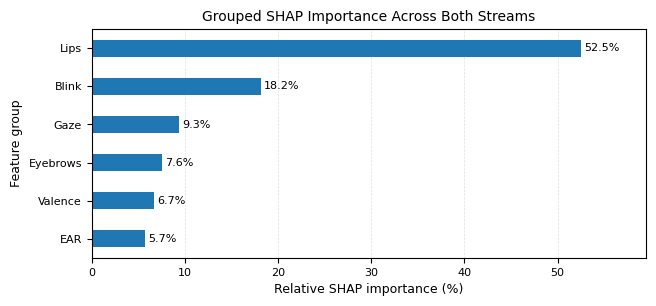


Files saved successfully:
1. Grouped_SHAP_Percentages_Both_Streams.pdf
2. Grouped_SHAP_Percentages_Both_Streams.png
3. Grouped_SHAP_Percentages_Both_Streams.csv
4. Individual_SHAP_Feature_Importance.csv


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# GROUPED SHAP IMPORTANCE — BOTH STREAMS
# ============================================================

# 1. Calculate mean absolute SHAP importance for every feature
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
})

# 2. Assign each feature to its corresponding group
def assign_group(feature_name):
    name = feature_name.lower()

    if "lip" in name or "mar" in name:
        return "Lips"

    elif "blink" in name:
        return "Blink"

    elif "brow" in name or "eyebrow" in name:
        return "Eyebrows"

    elif "ear" in name:
        return "EAR"

    elif "gaze" in name or "iris" in name:
        return "Gaze"

    elif "valence" in name:
        return "Valence"

    else:
        return "Other"


feature_importance["group"] = feature_importance["feature"].apply(
    assign_group
)

# 3. Check that all features were assigned correctly
unassigned_features = feature_importance[
    feature_importance["group"] == "Other"
]

if not unassigned_features.empty:
    print("Warning: the following features were assigned to 'Other':")
    print(unassigned_features[["feature"]].to_string(index=False))

# 4. Sum the mean absolute SHAP values within each group
grouped_shap = (
    feature_importance
    .groupby("group", as_index=False)["mean_abs_shap"]
    .sum()
)

# Keep 'Other' in the calculations if unassigned features exist
if unassigned_features.empty:
    grouped_shap = grouped_shap[
        grouped_shap["group"] != "Other"
    ].copy()

# 5. Convert grouped importance to percentages
total_importance = grouped_shap["mean_abs_shap"].sum()

grouped_shap["percentage"] = (
    grouped_shap["mean_abs_shap"] / total_importance
) * 100

# Sort from lowest to highest for the horizontal bar graph
grouped_shap = grouped_shap.sort_values(
    by="percentage",
    ascending=True
).reset_index(drop=True)

# Print numerical results
print("\nGrouped SHAP importance across both streams:\n")
print(
    grouped_shap[
        ["group", "mean_abs_shap", "percentage"]
    ].to_string(
        index=False,
        formatters={
            "mean_abs_shap": "{:.6f}".format,
            "percentage": "{:.2f}%".format
        }
    )
)

print(
    "\nTotal percentage:",
    f"{grouped_shap['percentage'].sum():.2f}%"
)

# ============================================================
# 6. COMPACT PUBLICATION-STYLE BAR GRAPH
# ============================================================

fig, ax = plt.subplots(figsize=(6.5, 3.0))

bars = ax.barh(
    grouped_shap["group"],
    grouped_shap["percentage"],
    height=0.45
)

ax.set_xlabel("Relative SHAP importance (%)", fontsize=9)
ax.set_ylabel("Feature group", fontsize=9)
ax.set_title(
    "Grouped SHAP Importance Across Both Streams",
    fontsize=10,
    pad=6
)

ax.tick_params(axis="both", labelsize=8)

# Add percentage labels at the end of every bar
for bar, percentage in zip(
    bars,
    grouped_shap["percentage"]
):
    ax.text(
        bar.get_width() + 0.35,
        bar.get_y() + bar.get_height() / 2,
        f"{percentage:.1f}%",
        va="center",
        ha="left",
        fontsize=8
    )

# Leave enough space for labels
maximum_percentage = grouped_shap["percentage"].max()

ax.set_xlim(0, maximum_percentage + 7)

# Light vertical grid lines
ax.grid(
    axis="x",
    linestyle="--",
    linewidth=0.5,
    alpha=0.4
)

ax.set_axisbelow(True)

plt.tight_layout(pad=0.5)

# 7. Save publication-quality files
plt.savefig(
    "Grouped_SHAP_Percentages_Both_Streams.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "Grouped_SHAP_Percentages_Both_Streams.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 8. SAVE NUMERICAL RESULTS
# ============================================================

grouped_shap.to_csv(
    "Grouped_SHAP_Percentages_Both_Streams.csv",
    index=False
)

feature_importance.sort_values(
    by="mean_abs_shap",
    ascending=False
).to_csv(
    "Individual_SHAP_Feature_Importance.csv",
    index=False
)

print("\nFiles saved successfully:")
print("1. Grouped_SHAP_Percentages_Both_Streams.pdf")
print("2. Grouped_SHAP_Percentages_Both_Streams.png")
print("3. Grouped_SHAP_Percentages_Both_Streams.csv")
print("4. Individual_SHAP_Feature_Importance.csv")

C:\Users\hp\AppData\Local\Temp\ipykernel_17436\291805031.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


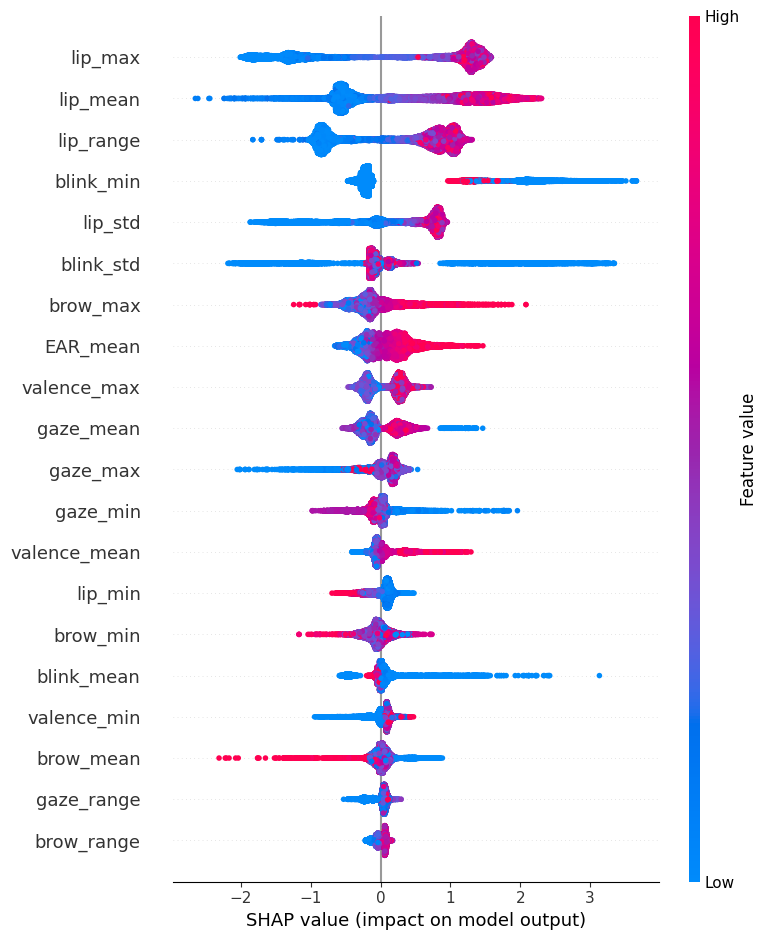

In [11]:
plt.figure(figsize=(10,8))

shap.summary_plot(
    shap_values,
    X_all_imp,
    feature_names=feature_names,
    show=False
)

plt.tight_layout()
plt.savefig("SHAP_summary.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# -----------------------------------
# SHAP values
# -----------------------------------

explainer = shap.TreeExplainer(shap_model)

shap_values = explainer.shap_values(X_all_imp)

# Binary classification compatibility
if isinstance(shap_values, list):
    shap_values = shap_values[1]

print("SHAP shape:", shap_values.shape)
print("Dataset shape:", X_all_imp.shape)

SHAP shape: (29736, 29)
Dataset shape: (29736, 29)


In [9]:
import shap
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier

# -------------------------------
# Combine both feature streams
# -------------------------------

X_all = pd.concat([X_geo, X_val], axis=1)

feature_names = X_all.columns.tolist()

# -------------------------------
# Imputation
# -------------------------------

imputer = SimpleImputer(strategy="mean")
X_all_imp = imputer.fit_transform(X_all)

# -------------------------------
# Canonical XGBoost model
# (same hyperparameters as Table 1)
# -------------------------------

shap_model = XGBClassifier(
    n_estimators=100,
    max_depth=4,
    learning_rate=0.1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
    verbosity=0
)

shap_model.fit(X_all_imp, y)

print("Model trained successfully.")

C:\Users\hp\anaconda3\envs\stress_ml\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model trained successfully.


In [8]:
fusion_rows = predictions_df[
    predictions_df["configuration"] == "Weighted Late Fusion"
]

assert len(fusion_rows) == len(df), (
    "The fused out-of-fold prediction count does not match "
    "the number of dataset samples."
)

assert fusion_rows["participant"].nunique() == pd.Series(groups).nunique(), (
    "Not every participant appears in the fused LOSO predictions."
)

assert np.allclose(
    fold_weights_df["weight_geo"] + fold_weights_df["weight_valence"],
    1.0
), "Fusion weights do not sum to 1."

results_df.to_csv(
    "canonical_xgboost_loso_results.csv",
    index=False
)

predictions_df.to_csv(
    "canonical_xgboost_loso_predictions.csv",
    index=False
)

fold_weights_df.to_csv(
    "canonical_xgboost_loso_fold_weights.csv",
    index=False
)

print("Consistency checks passed.")
print("\nFiles saved:")
print("- canonical_xgboost_loso_results.csv")
print("- canonical_xgboost_loso_predictions.csv")
print("- canonical_xgboost_loso_fold_weights.csv")


Consistency checks passed.

Files saved:
- canonical_xgboost_loso_results.csv
- canonical_xgboost_loso_predictions.csv
- canonical_xgboost_loso_fold_weights.csv


## Reporting rule

After running the notebook from a restarted kernel:

- Copy the **Weighted Late Fusion** metrics into the main XGBoost row.
- Use all three rows as the ablation-study table.
- Do not mix these results with outputs generated using another XGBoost configuration.
- Use this same `base_xgb_model` configuration in the SHAP notebook.
